In [ ]:
# !pip install roboflow

from roboflow import Roboflow
rf = Roboflow(api_key="ban8dhsPpPtklboVtLZI")
project = rf.workspace("face-mask-detection-aarne").project("face-mask-detection-tmy8p")
version = project.version(1)
dataset = version.download("yolov8")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 373.9/373.9 kB 30.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 136.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.4/58.4 kB 7.1 MB/s eta 0:00:00
  Attempting uninstall: typer
    Found existing installation: typer 0.27.2
    Uninstalling typer-0.27.2:
      Successfully uninstalled typer-0.27.2
loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to face-mask-detection-1 in yolov8:: 100%|██████████| 8691/8691 [00:01<00:00, 5601.69it/s]


In [2]:
import glob, yaml
from collections import Counter

with open(f"{dataset.location}/data.yaml") as f:
    names = yaml.safe_load(f)["names"]
print("classes:", names)

for split in ["train", "valid", "test"]:
    files = glob.glob(f"{dataset.location}/{split}/labels/*.txt")
    counts = Counter()
    for fp in files:
        for line in open(fp):
            if line.strip():
                counts[names[int(line.split()[0])]] += 1
    print(split, "| images:", len(files), "|", dict(counts))

classes: ['mask_weared_incorrect', 'with_mask', 'without_mask']
train | images: 3807 | {'without_mask': 5556, 'mask_weared_incorrect': 1572, 'with_mask': 5628}
valid | images: 356 | {'without_mask': 458, 'with_mask': 423, 'mask_weared_incorrect': 145}
test | images: 180 | {'without_mask': 227, 'mask_weared_incorrect': 74, 'with_mask': 296}


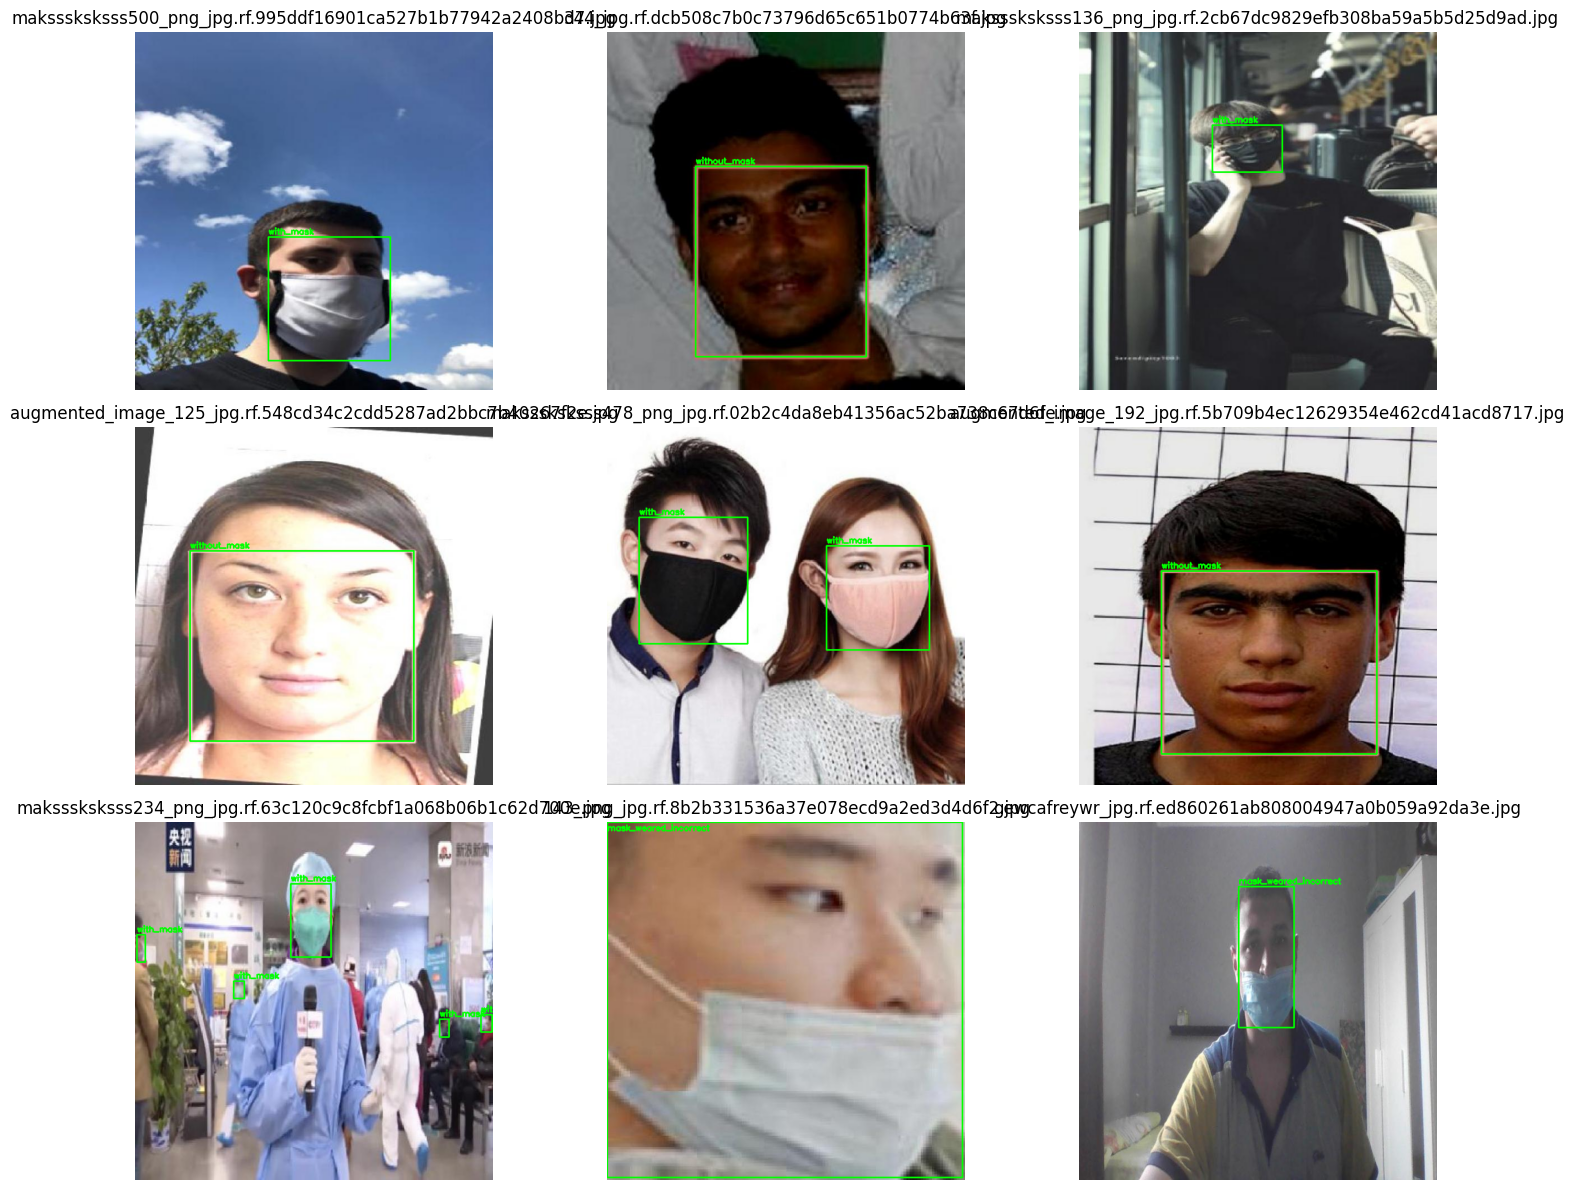

In [ ]:
import random
import os
import cv2
import matplotlib.pyplot as plt

val_images_dir = f"{dataset.location}/valid/images"
val_labels_dir = f"{dataset.location}/valid/labels"

image_paths = glob.glob(os.path.join(val_images_dir, "*"))
selected_images = random.sample(image_paths, min(9, len(image_paths)))

class_names = [
    "mask_weared_incorrect",
    "with_mask",
    "without_mask"
]

fig, axes = plt.subplots(3, 3, figsize=(15, 12))

for ax, img_path in zip(axes.flat, selected_images):
    img = cv2.imread(img_path)
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

    h, w = img.shape[:2]
    label_path = os.path.join(
        val_labels_dir,
        os.path.splitext(os.path.basename(img_path))[0] + ".txt"
    )

    if os.path.exists(label_path):
        with open(label_path, "r") as f:
            for line in f:
                cls, xc, yc, bw, bh = map(float, line.split()[:5])

                x1 = int((xc - bw / 2) * w)
                y1 = int((yc - bh / 2) * h)
                x2 = int((xc + bw / 2) * w)
                y2 = int((yc + bh / 2) * h)

                cv2.rectangle(img, (x1, y1), (x2, y2), (0, 255, 0), 2)

                label = class_names[int(cls)]
                cv2.putText(
                    img, label, (x1, max(y1 - 5, 15)),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.5, (0, 255, 0), 2
                )

    ax.imshow(img)
    ax.set_title(os.path.basename(img_path))
    ax.axis("off")

plt.tight_layout()
plt.show()


In [ ]:
# !pip install -U ultralytics

from ultralytics import YOLO

model = YOLO("yolo11n.pt")
model.train(
    data=f"{dataset.location}/data.yaml",
    epochs=50,
    imgsz=640,
    batch=16,
    project="/content/runs",
    name="mask",
)

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 4.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 66.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.6/97.6 kB 7.3 MB/s eta 0:00:00
Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Ultralytics 8.4.182 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/face-mask-detection-1/data.yaml, degrees=0.0, d

ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([0, 1, 2])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x7fb73cd96ba0>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.041041,    0.042042,    0.043043,    0.044044,    0.045045,    0.046046,    0.047047,
          0.04

In [5]:
best_model = YOLO("/content/runs/mask/weights/best.pt")

metrics = best_model.val(
    data=f"{dataset.location}/data.yaml",
    split="val",
    imgsz=640
)

print("mAP50:", metrics.box.map50, "| mAP50-95:", metrics.box.map)

Ultralytics 8.4.182 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11n summary (fused): 101 layers, 2,597,537 parameters, 0 gradients, 6.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1152.0±462.9 MB/s, size: 40.4 KB)
val: Scanning /content/face-mask-detection-1/valid/labels.cache... 356 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 356/356 71.1Mit/s 0.0s
val: /content/face-mask-detection-1/valid/images/301_jpg.rf.15f4ea6a17b11d8c9dbe46e4a8bdb484.jpg: 2 duplicate labels removed
val: /content/face-mask-detection-1/valid/images/301_jpg.rf.c1f2054b56f72511f2828bb45f45fed8.jpg: 2 duplicate labels removed
val: /content/face-mask-detection-1/valid/images/308_jpg.rf.16bea7a947acbb8d9a261f250cfce4b2.jpg: 2 duplicate labels removed
val: /content/face-mask-detection-1/valid/images/308_jpg.rf.f285853860bada88e3e1afc826e4489e.jpg: 2 duplicate labels removed
val: /content/face-mask-detection-1/valid/images/316_jpg.rf.1c64661e3f9d8483d01806a6503cd495.jpg: 2 dup

In [6]:
for key, value in metrics.results_dict.items():
    print(f"{key}: {value}")

metrics/precision(B): 0.8593599025805809
metrics/recall(B): 0.8544043520236823
metrics/mAP50(B): 0.8771794846409193
metrics/mAP50-95(B): 0.7136966352695248
fitness: 0.7136966352695248


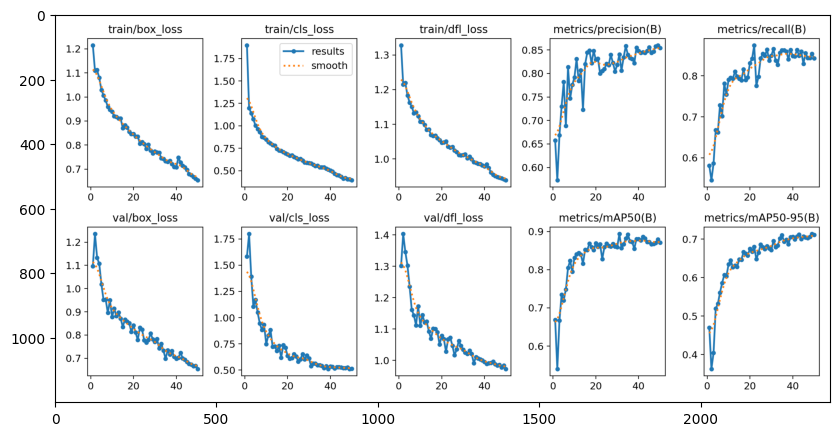

In [9]:
import matplotlib.pyplot as plt
img = plt.imread("/content/runs/mask/results.png")
plt.figure(figsize=(10,10))
plt.imshow(img)

In [31]:
# from IPython.display import display, Javascript
# from google.colab.output import eval_js
# from base64 import b64decode
# from ultralytics import YOLO
# from PIL import Image
# import io

# model = YOLO("/content/runs/mask/weights/best.pt")

# display(Javascript("""
# async function takePhoto() {
#   const div = document.createElement('div');
#   const btn = document.createElement('button');
#   btn.textContent = 'Take Photo';
#   div.appendChild(btn);

#   const video = document.createElement('video');
#   video.style.display = 'block';
#   div.appendChild(video);
#   document.body.appendChild(div);

#   const stream = await navigator.mediaDevices.getUserMedia({
#     video: true
#   });
#   video.srcObject = stream;
#   await video.play();

#   await new Promise(resolve => btn.onclick = resolve);

#   const canvas = document.createElement('canvas');
#   canvas.width = video.videoWidth;
#   canvas.height = video.videoHeight;
#   canvas.getContext('2d').drawImage(video, 0, 0);

#   stream.getTracks().forEach(track => track.stop());
#   div.remove();

#   return canvas.toDataURL('image/jpeg');
# }
# """))

# data = eval_js("takePhoto()")
# image_bytes = b64decode(data.split(",")[1])
# image = Image.open(io.BytesIO(image_bytes)).convert("RGB")

# results = model.predict(image, conf=0.25, imgsz=640)
# display(results[0].plot())

In [33]:
# from google.colab import files
# files.download("/content/runs/mask/weights/best.pt")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>